# 02 . Measure latency properly

Metrics:
- **TTFT** (time to first token): how long a user waits before text appears. Dominated by *prefill* (processing the prompt).
- **Decode speed** (tokens/s after the first token): how fast text streams. Dominated by memory bandwidth.
- **Total latency** for the whole answer

Method: warm-up runs (not recorded), then N repetitions, reports mean ± std, save raw results to CSV.

In [1]:
import os

from debugpy import trace_this_thread

os.environ["CUDA_DIVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import time, threading, platform, subprocess
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, TextIteratorStreamer

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
GPU_LABEL = "4060ti-egpu"
DEVICE = "cuda:0"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=torch.float, device_map=DEVICE).eval()
print(torch.cuda.get_device_name(0))

/home/thai-nguyen/thai/env/ai-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 338/338 [00:06<00:00, 54.45it/s] 


NVIDIA GeForce RTX 4060 Ti


## 1. The `measure()` function
`generate()` blocks until it is done, so we run it in a **background thread** and read tokens from a
`TextIteratorStreamer` in the main thread. The moment the first chunk arrives is our TTFT.

Note: the streamer yields *text chunks*, not exactly tokens. So we count generated tokens from the
final output instead of counting chunks.

In [2]:
def build_inputs(prompt: str):
    msgs = [{"role": "user", "content": prompt}]
    text = tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return tokenizer(text, return_tensors="pt").to(DEVICE)

def measure(model, prompt: str, max_new_tokens: int = 128) -> dict:
    inputs = build_inputs(prompt)
    streamer = TextIteratorStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True)
    result = {}

    def _run():
        with torch.inference_mode():
            result["out"] = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                min_new_tokens=max_new_tokens,
                do_sample=False,
                streamer=streamer,
                pad_token_id=tokenizer.eos_token_id,
            )

    torch.cuda.synchronize()
    t0 = time.perf_counter()
    th = threading.Thread(target=_run)
    th.start()
    ttft = None
    for chunk in streamer:
        if ttft is None and chunk:
            ttft = time.perf_counter() - t0
    th.join()
    torch.cuda.synchronize()
    total = time.perf_counter() - t0

    n_out = result["out"].shape[1] - inputs["input_ids"].shape[1]
    decode_s = max(total - ttft, 1e-9)
    return {
        "prompt_tokens": inputs["input_ids"].shape[1],
        "output_tokens": n_out,
        "ttft_s": ttft,
        "total_s": total,
        "decode_tok_s": (n_out - 1) / decode_s,
        "e2e_tok_s": n_out / total,
    }

measure(model, "Hello!", 16), # quick sanity check

({'prompt_tokens': 31,
  'output_tokens': 16,
  'ttft_s': 1.176075802000014,
  'total_s': 1.5447230370000398,
  'decode_tok_s': 40.68930559047581,
  'e2e_tok_s': 10.35784384433932},)

## 2. Experiment: vary `max_new_tokens`
Warm up first, then repeat each setting 5×.

In [3]:
PROMPT = "Explain step by step how Kubernetes schedules a pod onto a node."
LENGTHS = [32, 64, 128, 256, 512]
WARMUP, REPEATS = 3, 5

for _ in range(WARMUP):
    measure(model, PROMPT, 32)

rows = []
for n in LENGTHS:
    for r in range(REPEATS):
        m = measure(model, PROMPT, n)
        rows.append({"max_new_tokens": n, "repeat": r, **m})
    print(f"max_new_tokens={n} done")

df = pd.DataFrame(rows)
df.head()

max_new_tokens=32 done
max_new_tokens=64 done
max_new_tokens=128 done
max_new_tokens=256 done
max_new_tokens=512 done


,max_new_tokens,repeat,prompt_tokens,output_tokens,ttft_s,total_s,decode_tok_s,e2e_tok_s
0,32,0,43,32,0.085601,0.852652,40.414545,37.529982
1,32,1,43,32,0.086117,0.854358,40.351882,37.455004
2,32,2,43,32,0.086053,0.850282,40.563757,37.634591
3,32,3,43,32,0.087209,0.850153,40.632098,37.640280
4,32,4,43,32,0.086502,0.850443,40.579066,37.627469


## 3. Summary: mean ± std

In [4]:
summary = (df.groupby("max_new_tokens")[["ttft_s", "total_s", "decode_tok_s"]].agg(["mean", "std"]).round(3))
summary

ttft_s        total_s        decode_tok_s       
                 mean    std    mean    std         mean    std
max_new_tokens                                                 
32              0.086  0.001   0.852  0.002       40.508  0.119
64              0.088  0.003   1.702  0.006       39.027  0.129
128             0.087  0.002   3.414  0.006       38.179  0.073
256             0.086  0.001   6.905  0.005       37.396  0.026
512             0.087  0.000  14.095  0.023       36.479  0.060

## 4. Plot

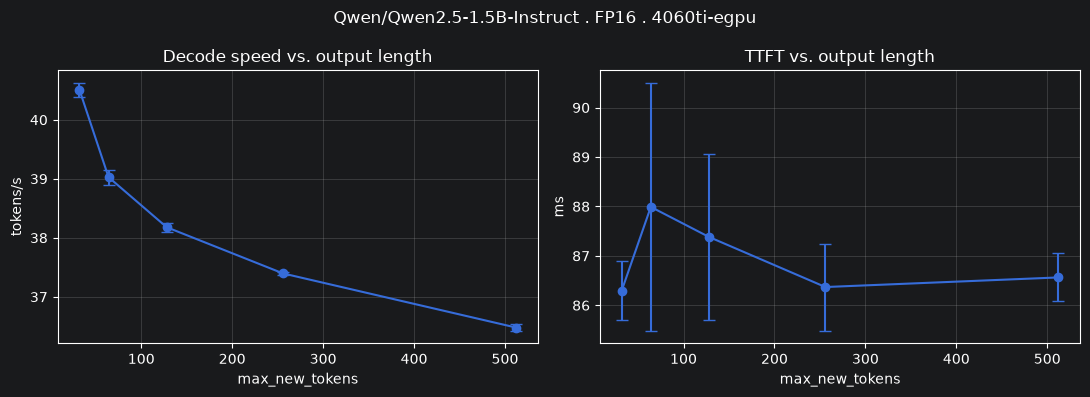

In [7]:
g = df.groupby("max_new_tokens")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(g.size().index, g["decode_tok_s"].mean(), yerr=g["decode_tok_s"].std(), marker="o", capsize=4)
axes[0].set(title="Decode speed vs. output length", xlabel="max_new_tokens", ylabel="tokens/s")
axes[1].errorbar(g.size().index, g["ttft_s"].mean() * 1000, yerr=g["ttft_s"].std() * 1000, marker="o", capsize=4)
axes[1].set(title="TTFT vs. output length", xlabel="max_new_tokens", ylabel="ms")
for ax in axes: ax.grid(alpha=.3)
fig.suptitle(f"{MODEL_ID} . FP16 . {GPU_LABEL}")
plt.tight_layout()
os.makedirs("../results/figures", exist_ok=True)
plt.savefig(f"../results/figures/02_decode_vs_length_{GPU_LABEL}.png", dpi=150)
plt.show()

## 5. Save raw results with metadata
Every result file should say *what produced it*.

In [8]:
def git_commit():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"]).decode().strip()
    except Exception:
        return "unknown"

df["model"] = MODEL_ID
df["dtype"] = "fp16"
df["engine"] = "transformers"
df["gpu"] = GPU_LABEL
df["gpu_name"] = torch.cuda.get_device_name(0)
df["torch"] = torch.__version__
df["git_commit"] = git_commit()
df["timestamp"] = datetime.now().isoformat(timespec="seconds")

os.makedirs("../results/raw", exist_ok=True)
path = f"../results/raw/02_latency_{GPU_LABEL}_{datetime.now():%Y%m%d-%H%M%S}.csv"
df.to_csv(path, index=False)
print("saved", path)

saved ../results/raw/02_latency_4060ti-egpu_20261027-125051.csv
